In [1]:
import torch
import torchaudio
import torchaudio.functional as F
import torchaudio.transforms as T

print(torch.__version__)
print(torchaudio.__version__)

import matplotlib.pyplot as plt

2.15.0+cu132
2.11.1+cu132


In [2]:
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
RECORDS = ROOT / "data" / "raw" / "inmp441" / "records"

SAMPLE_SPEECH = RECORDS / "cough" / "fococus_room_20261112_154810.wav"

In [6]:
from IPython.display import Audio
from matplotlib.patches import Rectangle
from torchaudio.utils import _download_asset

torch.random.manual_seed(0)

files = sorted(RECORDS.glob("*/*.wav"))
SAMPLE_SPEECH = files[0]


def plot_waveform(waveform, sr, title="Waveform", ax=None):
    waveform = waveform.numpy()

    num_channels, num_frames = waveform.shape
    time_axis = torch.arange(0, num_frames) / sr

    if ax is None:
        _, ax = plt.subplots(num_channels, 1)
    ax.plot(time_axis, waveform[0], linewidth=1)
    ax.grid(True)
    ax.set_xlim([0, time_axis[-1]])
    ax.set_title(title)


def plot_spectrogram(specgram, title=None, ylabel="freq_bin", ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1)
    if title is not None:
        ax.set_title(title)
    ax.set_ylabel(ylabel)
    power_to_db = T.AmplitudeToDB("power", 80.0)
    ax.imshow(power_to_db(specgram), origin="lower", aspect="auto", interpolation="nearest")


def plot_fbank(fbank, title=None):
    fig, axs = plt.subplots(1, 1)
    axs.set_title(title or "Filter bank")
    axs.imshow(fbank, aspect="auto")
    axs.set_ylabel("frequency bin")
    axs.set_xlabel("mel bin")


In [7]:
SPEECH_WAVEFORM, SAMPLE_RATE = torchaudio.load(SAMPLE_SPEECH)

# Define transform
spectrogram = T.Spectrogram(n_fft=512)

# Perform transform
spec = spectrogram(SPEECH_WAVEFORM)


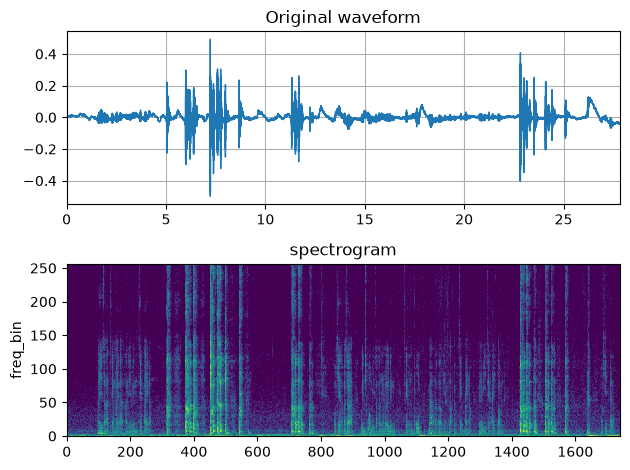

In [8]:
fig, axs = plt.subplots(2, 1)
plot_waveform(SPEECH_WAVEFORM, SAMPLE_RATE, title="Original waveform", ax=axs[0])
plot_spectrogram(spec[0], title="spectrogram", ax=axs[1])
fig.tight_layout()

In [9]:
Audio(SPEECH_WAVEFORM.numpy(), rate=SAMPLE_RATE)

In [10]:
n_ffts = [32, 128, 512, 2048]
hop_length = 64

specs = []
for n_fft in n_ffts:
    spectrogram = T.Spectrogram(n_fft=n_fft, hop_length=hop_length)
    spec = spectrogram(SPEECH_WAVEFORM)
    specs.append(spec)

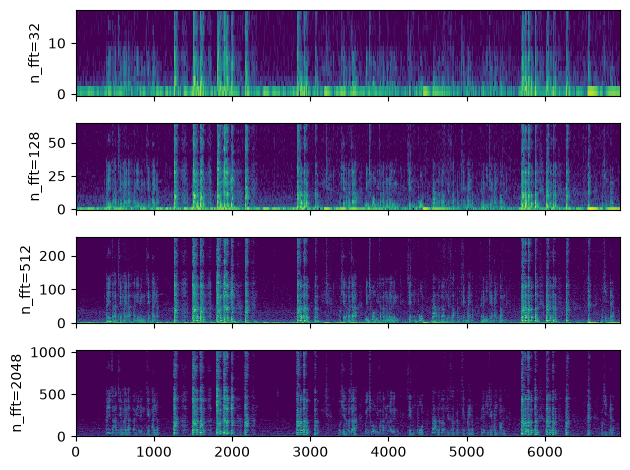

In [11]:
fig, axs = plt.subplots(len(specs), 1, sharex=True)
for i, (spec, n_fft) in enumerate(zip(specs, n_ffts)):
    plot_spectrogram(spec[0], ylabel=f"n_fft={n_fft}", ax=axs[i])
    axs[i].set_xlabel(None)
fig.tight_layout()

In [13]:
import pandas as pd

RECORDS = ROOT / "data" / "raw" / "inmp441" / "records"
df = pd.read_csv(ROOT / "data" / "manifest.csv" )
df.head()

,interim_path,raw_path,dataset,label,category,group,seconds,cough_detected
0,esc50/ESC-50-master/audio/1-100032-A-0.wav,esc50/ESC-50-master/audio/1-100032-A-0.wav,esc50,background,dog,esc50-100032,5.0,NaN
1,esc50/ESC-50-master/audio/1-100038-A-14.wav,esc50/ESC-50-master/audio/1-100038-A-14.wav,esc50,background,chirping_birds,esc50-100038,5.0,NaN
2,esc50/ESC-50-master/audio/1-100210-A-36.wav,esc50/ESC-50-master/audio/1-100210-A-36.wav,esc50,background,vacuum_cleaner,esc50-100210,5.0,NaN
3,esc50/ESC-50-master/audio/1-100210-B-36.wav,esc50/ESC-50-master/audio/1-100210-B-36.wav,esc50,background,vacuum_cleaner,esc50-100210,5.0,NaN
4,esc50/ESC-50-master/audio/1-101296-A-19.wav,esc50/ESC-50-master/audio/1-101296-A-19.wav,esc50,background,thunderstorm,esc50-101296,5.0,NaN


In [15]:
df["label"].value_counts()

label
cough         15166
speech        13200
background     1966
Name: count, dtype: int64

In [ ]:
df.groupby("label")["seconds"].sum()/ (60 * 60)

label
background     2.833166
cough         34.950278
speech         9.835794
Name: seconds, dtype: float64